In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/robinaz/us-equities/us_equities.csv


# **Python Practice: Stationarity and Autocorrelation**

In this practice, we check two problems with prices:
1. Are prices stationary?
2. Are prices autocorrelated?

Then we take the first difference (returns) and check again.

## **About the Data**

The file `us_equities.csv` contains daily closing prices downloaded from Bloomberg.

| Column | What it means |
|---|---|
| Date | Trading day (2 January 2015 – 31 December 2025) |
| SP500 | S&P 500 index level, in points. It tracks the 500 largest US companies. |
| MSFT | Microsoft share price, in US dollars. Microsoft is one of the companies in the S&P 500. |

There are 2,766 daily observations. There is no data for weekends or holidays because markets are closed.

## **Step 1: Import the Libraries**

Libraries are ready-made tools. We import them once at the start.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings
warnings.filterwarnings("ignore")

## **Step 2: Upload the Data**

Copy the file path from the right-hand sidebar in Kaggle and paste it inside the quotation marks.

In [3]:
df = pd.read_csv("/kaggle/input/datasets/robinaz/us-equities/us_equities.csv")

In [4]:
df.head()

,Date,SP500,MSFT
0,2015-01-02,2058.2000,39.6072
1,2015-01-05,2020.5800,39.2430
2,2015-01-06,2002.6100,38.6670
3,2015-01-07,2025.9000,39.1583
4,2015-01-08,2062.1399,40.3102


## **Step 3: Check Stationarity of Prices – Plot**

Look at the plot. Does each price return to the same level, or does it wander away?

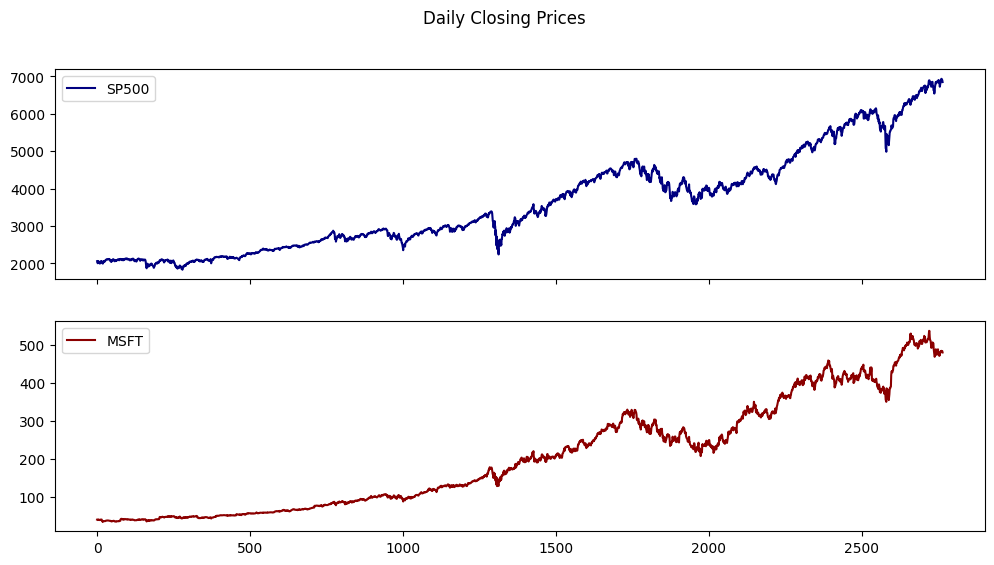

In [5]:
df.plot(subplots=True, figsize=(12, 6), title="Daily Closing Prices", color=["navy", "darkred"])
plt.show()

**Interpretation:** Both prices trend upwards over time and do not return to a fixed level. The average is not constant, so the prices look non-stationary. We now confirm this with a test.

## **Step 4: Check Stationarity of Prices – ADF Test (Unit Root Test)**

The ADF test checks whether the price has a unit root. A unit root means the price is non-stationary.

- H₀: The series has a unit root (non-stationary).
- H₁: The series is stationary.
- If p-value < 0.05 → reject H₀ → stationary.

In [6]:
print("S&P 500 ADF p-value:", round(adfuller(df["SP500"])[1], 4))
print("MSFT ADF p-value:", round(adfuller(df["MSFT"])[1], 4))

S&P 500 ADF p-value: 0.9918
MSFT ADF p-value: 0.9777


**Interpretation:** The p-values are 0.9918 (S&P 500) and 0.9777 (MSFT). Both are well above 0.05, so we cannot reject H₀. Both prices have a unit root and are **non-stationary**. This matches what we saw in the plot.

## **Step 5: Check Autocorrelation of Prices – ACF and PACF Plots**

- The **ACF** (autocorrelation function) shows the correlation between today's price and the price *s* days ago. It includes the indirect effect passed through the days in between.
- The **PACF** (partial autocorrelation function) shows the **direct** link between today's price and the price *s* days ago, after removing the effect of the days in between.

Bars outside the blue band are significant.

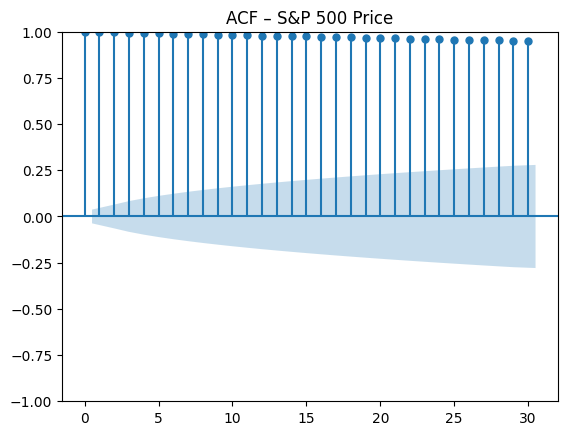

In [7]:
plot_acf(df["SP500"], lags=30, title="ACF – S&P 500 Price")
plt.show()

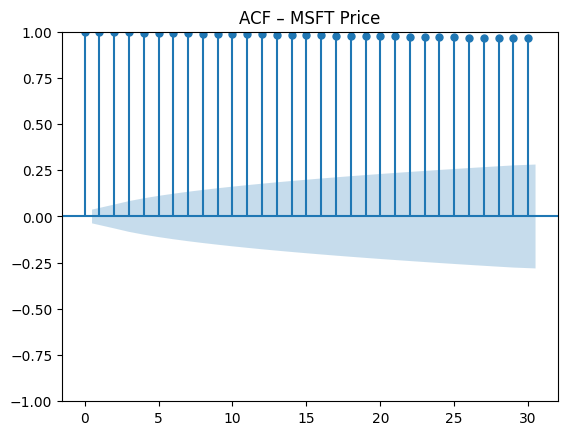

In [8]:
plot_acf(df["MSFT"], lags=30, title="ACF – MSFT Price")
plt.show()

**Interpretation:** All the bars are close to 1 and far outside the blue band. They fade very slowly. Today's price is almost the same as yesterday's price, so prices are strongly autocorrelated.

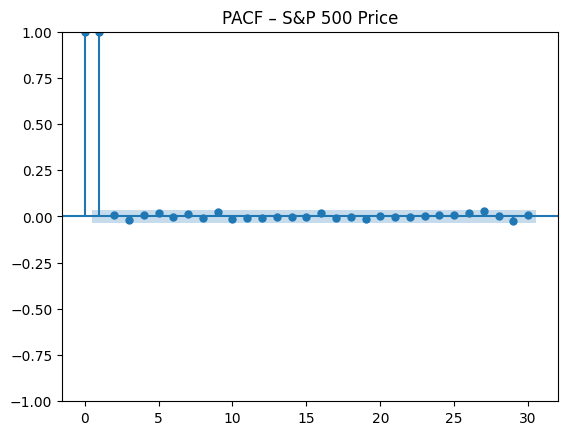

In [18]:
plot_pacf(df["SP500"], lags=30, title="PACF – S&P 500 Price")
plt.show()

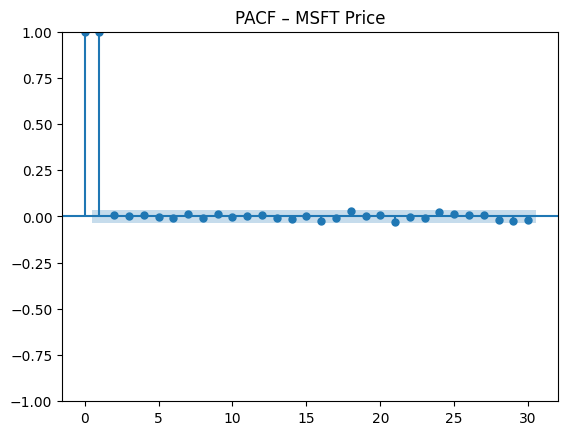

In [19]:
plot_pacf(df["MSFT"], lags=30, title="PACF – MSFT Price")
plt.show()

**Interpretation:** For both prices, only the lag 1 bar is close to 1. All the other bars are near zero. Today's price depends directly on yesterday's price only, which is a sign of a unit root (non-stationary).

## **Step 6: Check Autocorrelation of Prices – Ljung–Box Test**

The Ljung–Box test checks the first 10 lags together.

- H₀: There is no autocorrelation.
- H₁: There is autocorrelation.
- If p-value < 0.05 → reject H₀ → autocorrelated.

In [9]:
print("S&P 500 Ljung-Box p-value:", round(acorr_ljungbox(df["SP500"], lags=[10])["lb_pvalue"].iloc[0], 4))
print("MSFT Ljung-Box p-value:", round(acorr_ljungbox(df["MSFT"], lags=[10])["lb_pvalue"].iloc[0], 4))

S&P 500 Ljung-Box p-value: 0.0
MSFT Ljung-Box p-value: 0.0


**Interpretation:** Both p-values are 0.0, which is below 0.05, so we reject H₀. Prices are **heavily autocorrelated**. This confirms the ACF plots.

So prices have two problems: they are non-stationary and autocorrelated. Next, we fix this by taking the first difference.

## **Step 7: Take the First Difference (Returns)**

The first difference of the log price is the log return: today's log price minus yesterday's log price. We multiply by 100 to get returns in %. The first row is removed because it has no "yesterday".

In [10]:
returns = np.log(df[["SP500", "MSFT"]]).diff().dropna() * 100

In [11]:
returns.head()

,SP500,MSFT
1,-1.844722,-0.923784
2,-0.893327,-1.478656
3,1.156272,1.262588
4,1.773018,2.899213
5,-0.843931,-0.844034


## **Step 8: Check Stationarity of Returns – Plot**

Do the returns move around a fixed level?

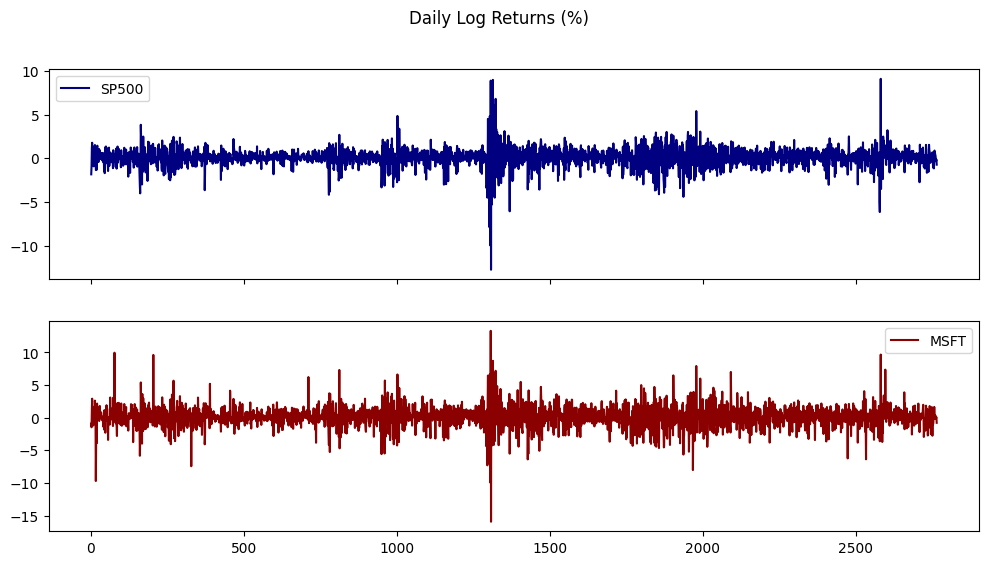

In [12]:
returns.plot(subplots=True, figsize=(12, 6), title="Daily Log Returns (%)", color=["navy", "darkred"])
plt.show()

**Interpretation:** Returns move up and down around zero and keep coming back to it. They look stationary. The big spikes in March 2020 are the COVID crash.

## **Step 9: Check Stationarity of Returns – ADF Test (Unit Root Test)**

- H₀: The series has a unit root (non-stationary).
- H₁: The series is stationary.
- If p-value < 0.05 → reject H₀ → stationary.

In [13]:
print("S&P 500 returns ADF p-value:", round(adfuller(returns["SP500"])[1], 4))
print("MSFT returns ADF p-value:", round(adfuller(returns["MSFT"])[1], 4))

S&P 500 returns ADF p-value: 0.0
MSFT returns ADF p-value: 0.0


**Interpretation:** Both p-values are 0.0, which is below 0.05, so we reject H₀. Returns have no unit root and are **stationary**. Taking the first difference has fixed Problem 1.

## **Step 10: Check Autocorrelation of Returns – ACF Plot**

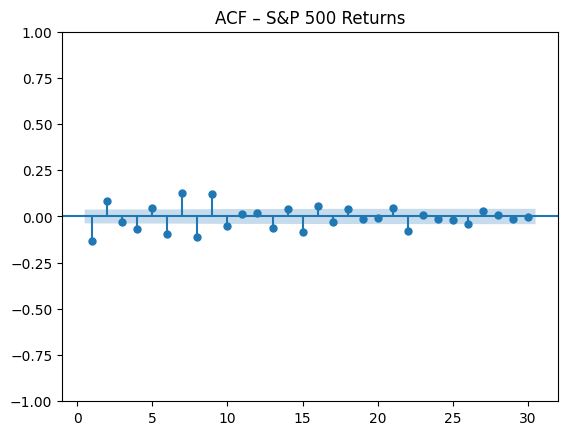

In [14]:
plot_acf(returns["SP500"], lags=30, zero=False, title="ACF – S&P 500 Returns")
plt.show()

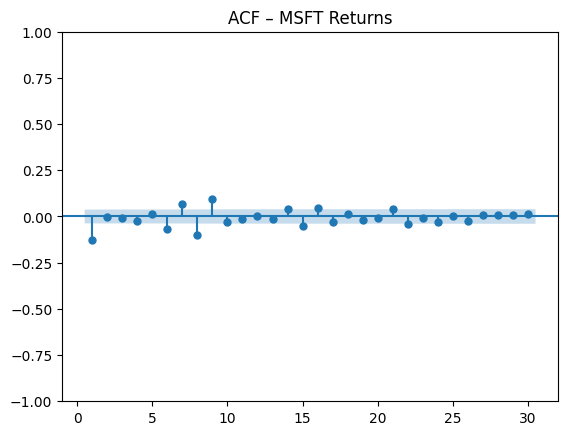

In [15]:
plot_acf(returns["MSFT"], lags=30, zero=False, title="ACF – MSFT Returns")
plt.show()

**Interpretation:** The bars are now very small, close to zero. A few bars go just outside the blue band, but they are tiny compared with the price ACF.

## **Step 11: Check Autocorrelation of Returns – Ljung–Box Test**

- H₀: There is no autocorrelation.
- H₁: There is autocorrelation.
- If p-value < 0.05 → reject H₀ → autocorrelated.

In [16]:
print("S&P 500 returns Ljung-Box p-value:", round(acorr_ljungbox(returns["SP500"], lags=[10])["lb_pvalue"].iloc[0], 4))
print("MSFT returns Ljung-Box p-value:", round(acorr_ljungbox(returns["MSFT"], lags=[10])["lb_pvalue"].iloc[0], 4))

S&P 500 returns Ljung-Box p-value: 0.0
MSFT returns Ljung-Box p-value: 0.0


**Interpretation:** The p-values are still below 0.05, so we reject H₀: there is **still some autocorrelation** in returns. But it is much smaller than for prices. The lag-1 autocorrelation falls from almost 1 (prices) to about −0.13 (returns). Most of what remains comes from the March 2020 COVID crash, when big falls and big rebounds followed each other. Our large sample (about 2,750 days) also makes even small autocorrelations "significant".

Taking the first difference has removed most of the autocorrelation, but not all of it. Later in the module, we will model what is left using ARMA models.

## **Conclusion**

| | Stationary? (Plot + ADF) | Autocorrelated? (ACF + Ljung–Box) |
|---|---|---|
| Prices | No, it has a unit root (p = 0.99) | Yes, strongly (bars near 1) |
| Returns (first difference) | Yes, no unit root (p = 0.00) | Very little (bars near 0) |

- Prices are **non-stationary** and **strongly autocorrelated**, so they are not safe to use in a regression.
- Taking the **first difference** turns prices into **returns**.
- Returns are **stationary** and have **very little autocorrelation**.

This is why, in finance, we model **returns, not prices**.